In [19]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR

In [2]:
df = pd.read_csv("powerplant_data.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [5]:
X = df.drop("PE", axis=1)
y = df["PE"]

In [6]:
# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Second split: divide temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# DEEP LEARNING FOR REGRESSION

In [7]:
# STEP 1: Convert data to tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

In [8]:
# STEP 2: Create TensorDataset and DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [9]:
#STEP 3: Define & build ANN Model
#3.1 Define ANN Model
class ANN(nn.Module):
     def __init__(self):
         super(ANN,self).__init__()
         self.module = nn.Sequential(
             # Creating 1st Hidden Layer
             nn.Linear(X_train.shape[1],6),
             nn.ReLU(),
             # Creating 2nd Hidden Layer
             nn.Linear(6,6),
             nn.ReLU(),
             # Creating output Layer
             nn.Linear(6,1)
         )
     def forward(self,x):
         return self.module(x)

In [10]:
#3.2 Build ANN Model
model = ANN()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [11]:
#STEP 4: Train , Validate  & Save Best Model

#4.1 Train 
train_losses = []
val_losses = []
best_val_loss = float("inf")

epochs = 100
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for xb,yb in train_loader:
        optimizer.zero_grad()
        outputs = model(xb) #forward propagation, generates output for this batch
        loss = criterion(outputs,yb) # compute loss for this batch
        loss.backward() # backward propagation, calculates gardients
        optimizer.step() # updates parameters
        running_loss += loss.item() # converting loss tensor to py float
    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)
    

#4.2 Validate
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for xb,yb in val_loader:
            outputs = model(xb)
            loss = criterion(outputs,yb)
            running_val_loss += loss.item()
    epoch_val_loss = running_val_loss / len(val_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")

#4.3 Save Best Model 
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(),"best_model.pt")


epoch 1/100 ==> train loss = 205931.4572172619 & val loss = 204699.50972222222
epoch 2/100 ==> train loss = 199888.6859375 & val loss = 192629.19479166667
epoch 3/100 ==> train loss = 178523.1935267857 & val loss = 161696.45347222223
epoch 4/100 ==> train loss = 139760.06651785714 & val loss = 118470.98177083333
epoch 5/100 ==> train loss = 98060.27806919643 & val loss = 81736.31024305556
epoch 6/100 ==> train loss = 69211.0609561012 & val loss = 59691.93125
epoch 7/100 ==> train loss = 51508.64982328869 & val loss = 44601.03029513889
epoch 8/100 ==> train loss = 37741.52890625 & val loss = 31617.767838541666
epoch 9/100 ==> train loss = 25820.08812313988 & val loss = 20747.36642795139
epoch 10/100 ==> train loss = 16385.906143043154 & val loss = 12820.68947482639
epoch 11/100 ==> train loss = 10094.175511532738 & val loss = 8117.677256944445
epoch 12/100 ==> train loss = 6694.134068080357 & val loss = 5723.061773003472
epoch 13/100 ==> train loss = 4887.089005533854 & val loss = 4298.

In [12]:
#STEP 5: Load Best Model
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [13]:
#STEP 6: Evaluation
model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criterion(train_preds,y_train_tensor)
    test_mse_loss = criterion(test_preds,y_test_tensor)
    
print("Training MSE:", train_mse_loss.item())
print("Testing MSE:", test_mse_loss.item())

Training MSE: 21.192089080810547
Testing MSE: 20.62004280090332


In [14]:
print("r^2 score =", r2_score(y_test, test_preds))

r^2 score = 0.929411831489954


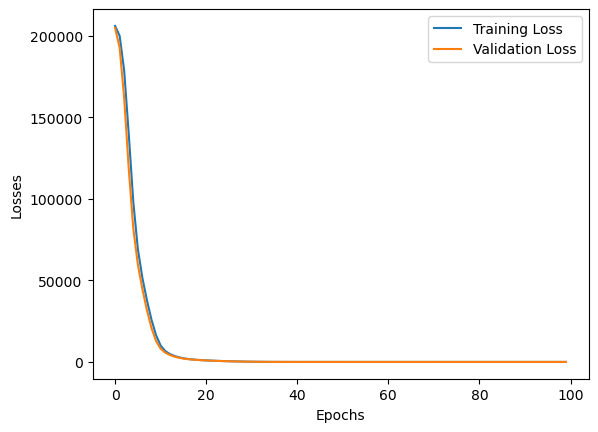

In [15]:
#Visualization
loss_df = pd.DataFrame({
    "Training Loss" : train_losses,
    "Validation Loss" : val_losses
})

plt.plot(loss_df["Training Loss"], label = "Training Loss")
plt.plot(loss_df["Validation Loss"], label = "Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

# Linear Regression

In [20]:
linear_model = LinearRegression()
linear_model.fit(X_train_scaled,y_train)
y_pred = linear_model.predict(X_test_scaled)
print(f"Linear Regression MSE:", mean_squared_error(y_test, y_pred))
print(f"R2 score with linear regression = {r2_score(y_test,y_pred)*100}%")

Linear Regression MSE: 20.38085554162044
R2 score with linear regression = 93.02306404647715%


# Support Vector Machine

In [21]:
svr = SVR()
svr.fit(X_train_scaled,y_train)
y_pred = svr.predict(X_test_scaled)
print(f"SVR MSE:", mean_squared_error(y_test, y_pred))
print(f"R2 score with SVR = {r2_score(y_test,y_pred)*100}%")

SVR MSE: 16.689473902435537
R2 score with SVR = 94.28672705728692%
